# GoEmotions project proposition

**Question.** On short Reddit comments, how do document representation and classifier depth affect multilabel emotion recognition?

This notebook is the self-contained experiment for the assignment. It keeps BPE training on **all official training texts**, uses repeated multilabel-stratified cross-validation on the training split, selects one global decision threshold per system from out-of-fold predictions, and evaluates the selected system on the untouched test split only once.

| Requirement | Choices |
|---|---|
| Representations | BPE token indicators; BPE token-count bag of words; BPE TF-IDF |
| Architectures | one-vs-rest log-linear; one-hidden-layer MLP; two-hidden-layer MLP |
| Primary metric | macro-F1, with micro-F1, precision, recall, and Hamming loss |
| Statistical comparison | repeated paired CV and Bayesian correlated-$t$ posterior with a justified ROPE |

The tutorial's multiclass softmax models cannot represent multiple simultaneous emotions. The GoEmotions adaptation therefore uses 28 independent binary decisions.

In [1]:
# Phase 1: portable setup, data loading, and train-wide BPE
from pathlib import Path
import sys
import csv
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import baycomp
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.multiclass import OneVsRestClassifier
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Metaspace
from tokenizers.trainers import BpeTrainer

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / 'NLP1_2026' / 'NLP_group40' / 'part1' / 'goemotions_pipeline.py').exists():
        sys.path.insert(0, str(candidate / 'NLP1_2026' / 'NLP_group40' / 'part1'))
        break
    if (candidate / 'goemotions_pipeline.py').exists():
        sys.path.insert(0, str(candidate))
        break

from goemotions_pipeline import (
    dataset_audit, load_splits, locate_data, multilabel_metrics,
    select_global_threshold, validate_binary_targets,
)

warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED = 0
CV_SEEDS = [0, 3, 5]
N_SPLITS = 5
QUICK_RUN = False
MAX_ROWS = 6_000 if QUICK_RUN else None
BPE_VOCAB_SIZE = 1_000
BPE_MIN_FREQUENCY = 2
ROPE = 0.005
THRESHOLDS = np.arange(0.10, 0.91, 0.05)

DATA_DIR = locate_data(Path.cwd())
SPLITS, TARGETS, LABELS = load_splits(DATA_DIR)
validate_binary_targets(list(TARGETS.values()))
train = SPLITS['train']
if MAX_ROWS is not None:
    rng = np.random.default_rng(SEED)
    selected = np.sort(rng.choice(len(train), MAX_ROWS, replace=False))
    X_cv = train.iloc[selected]['text'].reset_index(drop=True)
    Y_cv = TARGETS['train'][selected]
else:
    X_cv = train['text'].reset_index(drop=True)
    Y_cv = TARGETS['train']

RESULTS_DIR = DATA_DIR.parent / 'goemotions_results'
RESULTS_DIR.mkdir(exist_ok=True)
PLOTS_DIR = RESULTS_DIR / 'plots'
PLOTS_DIR.mkdir(exist_ok=True)
BPE_PATH = RESULTS_DIR / f'bpe_vs{BPE_VOCAB_SIZE}_mf{BPE_MIN_FREQUENCY}.json'
tokenizer = Tokenizer(BPE(unk_token='[UNK]'))
tokenizer.pre_tokenizer = Metaspace()
tokenizer.train_from_iterator(
    train['text'],
    trainer=BpeTrainer(vocab_size=BPE_VOCAB_SIZE, min_frequency=BPE_MIN_FREQUENCY, special_tokens=['[UNK]']),
)
tokenizer.save(str(BPE_PATH))
BPE_VOCAB = tokenizer.get_vocab()

def bpe_analyzer(text):
    return tokenizer.encode(text).tokens

print(f'Data: {DATA_DIR}')
print(f'CV rows: {len(X_cv):,}; labels: {len(LABELS)}; BPE vocabulary: {len(BPE_VOCAB):,}')
print(f'CV seeds: {CV_SEEDS}; folds per seed: {N_SPLITS}; global threshold candidates: {THRESHOLDS.tolist()}')

Data: C:\Users\Matth\MSC_AI\NLP1_2026\data
CV rows: 43,410; labels: 28; BPE vocabulary: 1,000
CV seeds: [0, 3, 5]; folds per seed: 5; global threshold candidates: [0.1, 0.15000000000000002, 0.20000000000000004, 0.25000000000000006, 0.30000000000000004, 0.3500000000000001, 0.40000000000000013, 0.45000000000000007, 0.5000000000000001, 0.5500000000000002, 0.6000000000000002, 0.6500000000000001, 0.7000000000000002, 0.7500000000000002, 0.8000000000000002, 0.8500000000000002, 0.9000000000000002]


## Phases 1?3: dataset audit, EDA, and multilabel targets

The downloaded TSV files are headerless and contain `text`, comma-separated label IDs, and an ID. The following tables verify missing values, duplicates, label cardinality, character lengths, imbalance, and cross-split text overlap.

,split,examples,missing,duplicate_text,mean_labels,multilabel_percent,mean_chars,median_chars,p95_chars
0,train,43410,0,183,1.177,16.360,68.505,65.0,131.0
1,dev,5426,0,3,1.176,16.181,68.351,65.0,133.0
2,test,5427,0,6,1.166,15.423,67.939,65.0,132.0


,left,right,shared_ids,shared_texts
0,train,dev,0,41
1,train,test,0,32
2,dev,test,0,10


,label,count,split
27,neutral,14219,train
0,admiration,4130,train
4,approval,2939,train
15,gratitude,2662,train
3,annoyance,2470,train
1,amusement,2328,train
7,curiosity,2191,train
18,love,2086,train
10,disapproval,2022,train
20,optimism,1581,train


Target shape: (43410, 28) | training multilabel percentage: 16.360285648468096


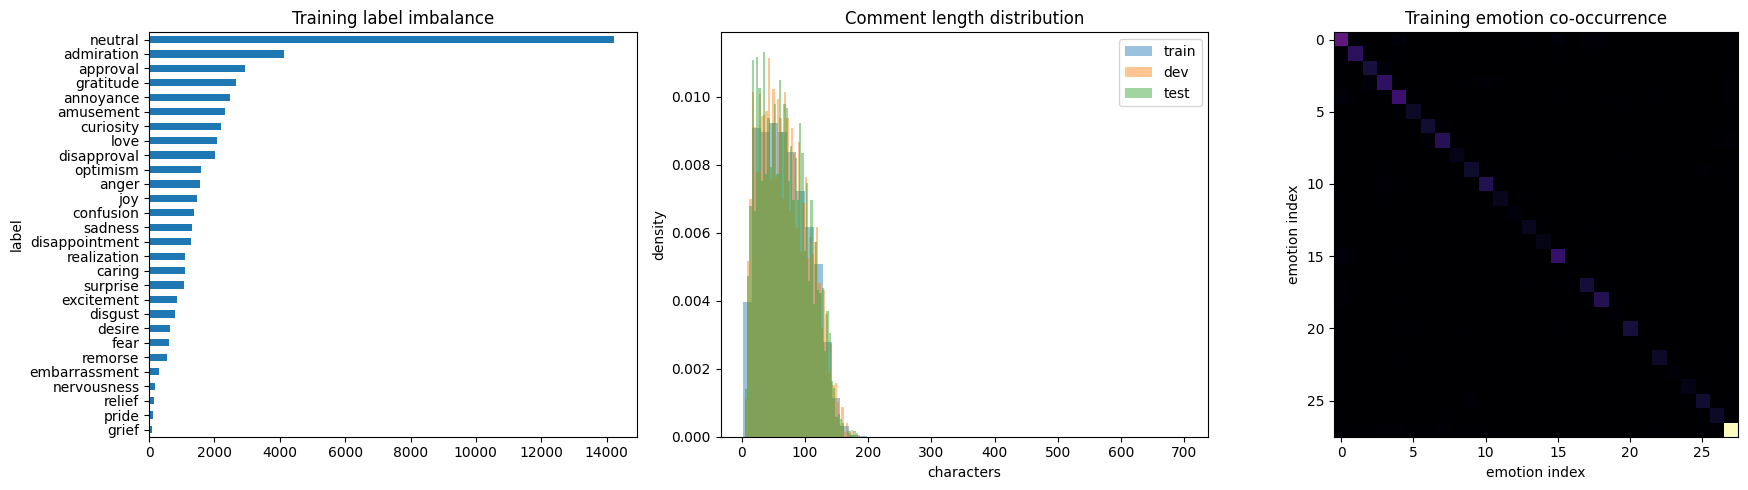

In [2]:
# Phase 2: complete EDA and leakage checks
summary, label_counts, overlaps = dataset_audit(SPLITS, TARGETS)
display(summary.round(3))
display(overlaps)
label_table = (label_counts[label_counts['split'].eq('train')]
               .assign(label=lambda frame: frame['label'].map(dict(enumerate(LABELS))))
               .sort_values('count', ascending=False))
display(label_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
label_table.sort_values('count').plot.barh(x='label', y='count', ax=axes[0], legend=False, title='Training label imbalance')
for name, frame in SPLITS.items():
    axes[1].hist(frame['text'].str.len(), bins=50, alpha=.45, label=name, density=True)
axes[1].set(title='Comment length distribution', xlabel='characters', ylabel='density')
axes[1].legend()
cooccurrence = TARGETS['train'].T @ TARGETS['train']
axes[2].imshow(cooccurrence, cmap='magma')
axes[2].set(title='Training emotion co-occurrence', xlabel='emotion index', ylabel='emotion index')
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'eda_overview.png', dpi=180, bbox_inches='tight')

assert all(summary['missing'].eq(0))
assert all(overlaps['shared_ids'].eq(0))
print('Target shape:', TARGETS['train'].shape, '| training multilabel percentage:', summary.loc[summary.split.eq('train'), 'multilabel_percent'].iat[0])

## Phases 4?6: representations, architectures, and repeated paired CV

BPE is deliberately trained once on all official training texts, matching the tutorial decision. Vectorizer IDF values and model parameters are still fitted separately inside each training fold. Every system receives the same fold assignments. A single global threshold is selected per system from its concatenated out-of-fold predictions, rather than tuning separate thresholds per emotion.

In [3]:
# Phase 3: controlled 3 x 3 design
bpe_args = dict(analyzer=bpe_analyzer, vocabulary=BPE_VOCAB, lowercase=False)
representations = {
    'BPE indicator': CountVectorizer(binary=True, **bpe_args),
    'BPE count': CountVectorizer(binary=False, **bpe_args),
    'BPE tfidf': TfidfVectorizer(sublinear_tf=True, norm='l2', **bpe_args),
}
architectures = {
    'log-linear': OneVsRestClassifier(
        LogisticRegression(solver='liblinear', max_iter=100, random_state=SEED), n_jobs=1),
    'MLP-1': MLPClassifier(hidden_layer_sizes=(128,), activation='relu', solver='adam',
                           batch_size=64, learning_rate_init=1e-4, alpha=1e-4,
                           max_iter=10, early_stopping=False, random_state=SEED),
    'MLP-2': MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam',
                           batch_size=64, learning_rate_init=1e-4, alpha=1e-4,
                           max_iter=10, early_stopping=False, random_state=SEED),
}
systems = {f'{rep} + {arch}': make_pipeline(clone(vectorizer), clone(model))
           for rep, vectorizer in representations.items()
           for arch, model in architectures.items()}
display(pd.DataFrame([(rep, arch, f'{rep} + {arch}')
                      for rep in representations for arch in architectures],
                     columns=['representation', 'architecture', 'system']))

,representation,architecture,system
0,BPE indicator,log-linear,BPE indicator + log-linear
1,BPE indicator,MLP-1,BPE indicator + MLP-1
2,BPE indicator,MLP-2,BPE indicator + MLP-2
3,BPE count,log-linear,BPE count + log-linear
4,BPE count,MLP-1,BPE count + MLP-1
5,BPE count,MLP-2,BPE count + MLP-2
6,BPE tfidf,log-linear,BPE tfidf + log-linear
7,BPE tfidf,MLP-1,BPE tfidf + MLP-1
8,BPE tfidf,MLP-2,BPE tfidf + MLP-2


In [4]:
# Phase 7: repeated multilabel-stratified CV and out-of-fold threshold selection
def probability_array(model, texts):
    probabilities = model.predict_proba(texts)
    if isinstance(probabilities, list):
        probabilities = np.column_stack([item[:, 1] for item in probabilities])
    return np.asarray(probabilities, dtype=np.float32)

fold_rows = []
fit_rows = []
oof = {}
for system_name, prototype in systems.items():
    system_gold, system_probabilities, fold_parts = [], [], []
    started = time.time()
    for run, seed in enumerate(CV_SEEDS):
        splitter = MultilabelStratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
        for fold, (train_idx, validation_idx) in enumerate(splitter.split(X_cv, Y_cv)):
            model = clone(prototype)
            model.fit(X_cv.iloc[train_idx], Y_cv[train_idx])
            probabilities = probability_array(model, X_cv.iloc[validation_idx])
            system_gold.append(Y_cv[validation_idx])
            system_probabilities.append(probabilities)
            fold_parts.append((run, fold, Y_cv[validation_idx], probabilities))
            fit_rows.append({
                'system': system_name, 'run': run, 'seed': seed, 'fold': fold,
                'n_train': len(train_idx), 'n_validation': len(validation_idx),
                'fit_seconds': time.time() - started,
            })
    gold = np.vstack(system_gold)
    probabilities = np.vstack(system_probabilities)
    threshold, threshold_table = select_global_threshold(gold, probabilities, THRESHOLDS)
    oof[system_name] = {'gold': gold, 'probabilities': probabilities,
                        'threshold': threshold, 'threshold_table': threshold_table,
                        'fold_parts': fold_parts}
    for run, fold, fold_gold, fold_probabilities in fold_parts:
        fold_metric = multilabel_metrics(fold_gold, fold_probabilities, threshold)
        fold_rows.append({'system': system_name, 'run': run, 'seed': CV_SEEDS[run],
                          'fold': fold, 'threshold': threshold, **fold_metric})
    print(f'{system_name:28s} threshold={threshold:.2f} elapsed={(time.time() - started) / 60:.1f} min')

summary_rows = []
for system_name, result in oof.items():
    metrics = multilabel_metrics(result['gold'], result['probabilities'], result['threshold'])
    summary_rows.append({'system': system_name, 'threshold': result['threshold'], **metrics})
summary = pd.DataFrame(summary_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
fold_table = pd.DataFrame(fold_rows)
fit_table = pd.DataFrame(fit_rows)
summary.to_csv(RESULTS_DIR / 'cv_summary.csv', index=False)
fold_table.to_csv(RESULTS_DIR / 'repeated_cv_scores.csv', index=False)
fit_table.to_csv(RESULTS_DIR / 'fit_metadata.csv', index=False)
display(summary.round(4))

BPE indicator + log-linear   threshold=0.15 elapsed=2.3 min


BPE indicator + MLP-1        threshold=0.10 elapsed=5.3 min


BPE indicator + MLP-2        threshold=0.10 elapsed=6.0 min


BPE count + log-linear       threshold=0.15 elapsed=3.9 min


BPE count + MLP-1            threshold=0.10 elapsed=5.9 min


BPE count + MLP-2            threshold=0.10 elapsed=6.1 min


BPE tfidf + log-linear       threshold=0.10 elapsed=1.9 min


BPE tfidf + MLP-1            threshold=0.10 elapsed=6.1 min


BPE tfidf + MLP-2            threshold=0.10 elapsed=6.2 min


,system,threshold,macro_f1,micro_f1,macro_precision,micro_precision,macro_recall,micro_recall,hamming_loss
0,BPE indicator + log-linear,0.15,0.3617,0.4703,0.3187,0.3786,0.4308,0.6206,0.0588
1,BPE tfidf + log-linear,0.10,0.3532,0.4500,0.3390,0.3376,0.4498,0.6749,0.0693
2,BPE count + log-linear,0.15,0.3528,0.4669,0.3122,0.3786,0.4155,0.6088,0.0585
3,BPE indicator + MLP-1,0.10,0.2844,0.4285,0.3158,0.3249,0.3591,0.6290,0.0705
4,BPE count + MLP-1,0.10,0.2838,0.4274,0.3099,0.3241,0.3590,0.6276,0.0707
5,BPE indicator + MLP-2,0.10,0.2798,0.4297,0.2714,0.3263,0.3635,0.6288,0.0702
6,BPE count + MLP-2,0.10,0.2797,0.4287,0.2677,0.3260,0.3617,0.6259,0.0701
7,BPE tfidf + MLP-2,0.10,0.1738,0.4039,0.2624,0.3293,0.2242,0.5221,0.0648
8,BPE tfidf + MLP-1,0.10,0.1434,0.3783,0.2933,0.3113,0.1809,0.4821,0.0666


architecture,log-linear,MLP-1,MLP-2
representation,,,
BPE indicator,0.3617,0.2844,0.2798
BPE count,0.3528,0.2838,0.2797
BPE tfidf,0.3532,0.1434,0.1738


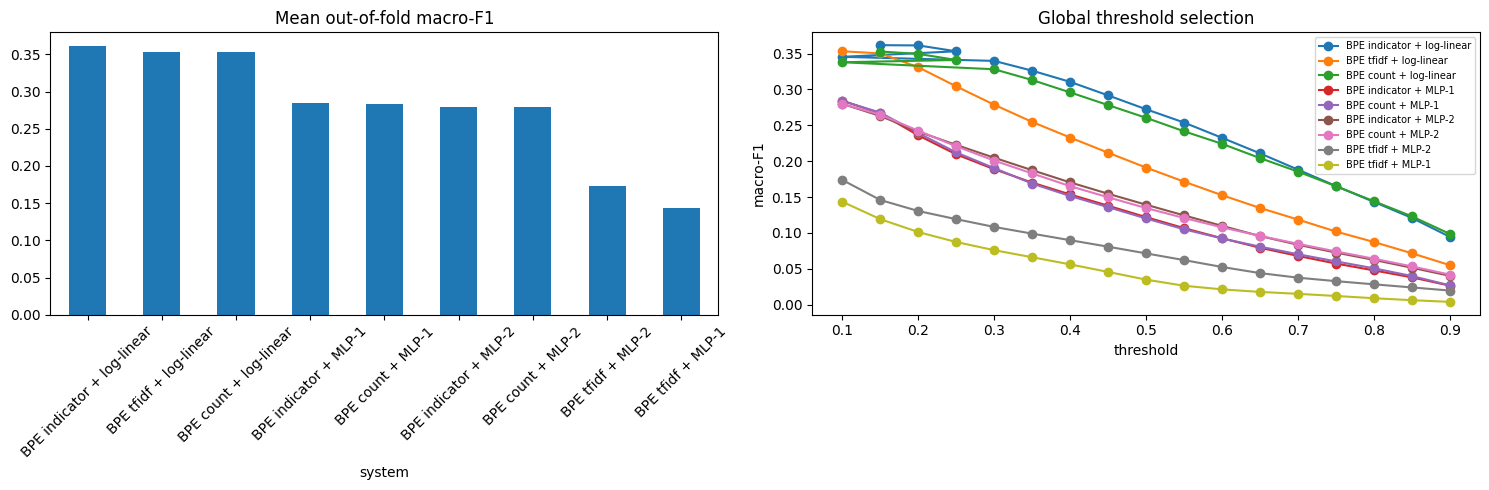

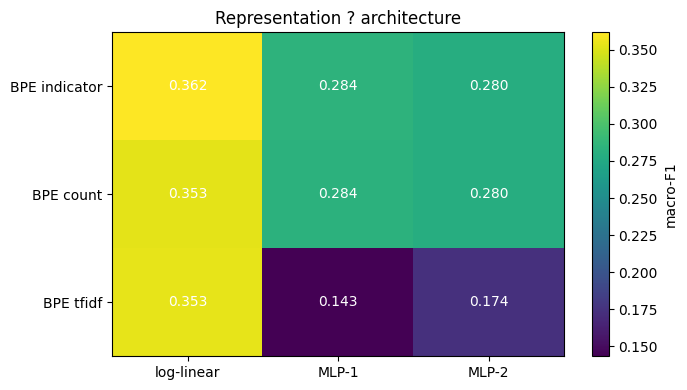

In [5]:
# Phase 8: comparison figures and threshold evidence
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
summary.plot.bar(x='system', y='macro_f1', ax=axes[0], legend=False, title='Mean out-of-fold macro-F1')
axes[0].tick_params(axis='x', rotation=45)
for system_name in summary['system']:
    table = oof[system_name]['threshold_table']
    axes[1].plot(table['threshold'], table['macro_f1'], marker='o', label=system_name)
axes[1].set(title='Global threshold selection', xlabel='threshold', ylabel='macro-F1')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'representation_architecture_heatmap.png', dpi=180, bbox_inches='tight')
fig.savefig(PLOTS_DIR / 'threshold_and_model_comparison.png', dpi=180, bbox_inches='tight')

score_matrix = (summary.assign(representation=summary.system.str.rsplit(' + ', n=1).str[0],
                               architecture=summary.system.str.rsplit(' + ', n=1).str[1])
                .pivot(index='representation', columns='architecture', values='macro_f1')
                .reindex(index=representations, columns=architectures))
display(score_matrix.round(4))
plt.figure(figsize=(7, 4))
plt.imshow(score_matrix, cmap='viridis', aspect='auto')
plt.xticks(range(len(score_matrix.columns)), score_matrix.columns)
plt.yticks(range(len(score_matrix.index)), score_matrix.index)
plt.colorbar(label='macro-F1')
plt.title('Representation ? architecture')
for i in range(score_matrix.shape[0]):
    for j in range(score_matrix.shape[1]):
        plt.text(j, i, f'{score_matrix.iloc[i, j]:.3f}', ha='center', va='center', color='white')
plt.tight_layout()

## Phases 8?9: Bayesian ROPE comparison and final held-out evaluation

The ROPE is ?0.005 macro-F1: a half-percentage-point difference is treated as practically negligible. This is a transparent adaptation of the tutorial convention, not a claim that the value is application-independent.

A=BPE indicator + log-linear; B=BPE tfidf + log-linear
P(A wins)=0.882 | P(ROPE)=0.118 | P(B wins)=0.000
posterior mean B-A=-0.0083; effect size=-3.13


,A,B,P(A wins),P(practical tie),P(B wins),mean B-A,ROPE
0,BPE indicator + log-linear,BPE tfidf + log-linear,0.882,0.1179,0.0001,-0.0083,0.005


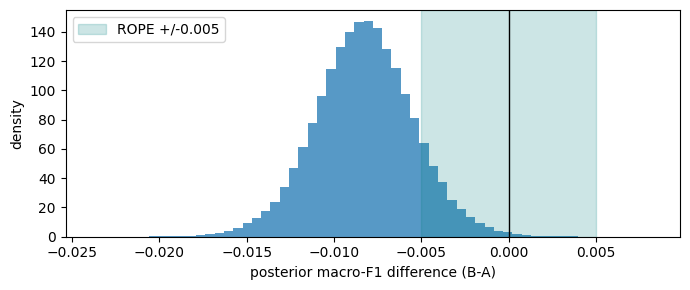

In [6]:
# Phase 9: Bayesian comparison of the two highest-ranked systems
A, B = summary.loc[0, 'system'], summary.loc[1, 'system']
paired = pd.DataFrame({
    'A': [row['macro_f1'] for row in fold_rows if row['system'] == A],
    'B': [row['macro_f1'] for row in fold_rows if row['system'] == B],
})
posterior = baycomp.CorrelatedTTest(
    paired['A'].to_numpy(), paired['B'].to_numpy(), rope=ROPE, runs=len(CV_SEEDS)
)
p_A, p_rope, p_B = posterior.probs()
print(f'A={A}; B={B}')
print(f'P(A wins)={p_A:.3f} | P(ROPE)={p_rope:.3f} | P(B wins)={p_B:.3f}')
print(f'posterior mean B-A={posterior.mean:.4f}; effect size={posterior.mean / np.sqrt(posterior.var):.2f}')
posterior_table = pd.DataFrame([{'A': A, 'B': B, 'P(A wins)': p_A,
                                  'P(practical tie)': p_rope, 'P(B wins)': p_B,
                                  'mean B-A': posterior.mean, 'ROPE': ROPE}])
display(posterior_table.round(4))
plt.figure(figsize=(7, 3))
plt.hist(np.asarray(posterior.sample), bins=60, density=True, alpha=.75)
plt.axvspan(-ROPE, ROPE, color='teal', alpha=.2, label=f'ROPE +/-{ROPE}')
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('posterior macro-F1 difference (B-A)')
plt.ylabel('density')
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'bayesian_rope_posterior.png', dpi=180, bbox_inches='tight')


Selected system: BPE indicator + log-linear | global threshold: 0.15000000000000002


,BPE indicator + log-linear
macro_f1,0.360756
micro_f1,0.480485
macro_precision,0.322261
micro_precision,0.387506
macro_recall,0.427302
micro_recall,0.632169
hamming_loss,0.056938
subset_accuracy,0.214115


,label,support,predicted,precision,recall,f1
0,nervousness,23,24,0.000000,0.000000,0.000000
1,relief,11,11,0.000000,0.000000,0.000000
2,grief,6,5,0.000000,0.000000,0.000000
3,disappointment,151,154,0.181818,0.185430,0.183607
4,annoyance,320,358,0.215084,0.240625,0.227139
5,caring,135,173,0.225434,0.288889,0.253247
6,embarrassment,37,41,0.243902,0.270270,0.256410
7,realization,145,111,0.306306,0.234483,0.265625
8,confusion,153,278,0.208633,0.379085,0.269142
9,approval,351,568,0.223592,0.361823,0.276387


,text,gold,predicted
0,I’m really sorry about your situation :( Altho...,sadness,"love, remorse, sadness"
1,It's wonderful because it's awful. At not with.,admiration,"admiration, disgust"
2,"Kings fan here, good luck to you guys! Will be...",excitement,"admiration, excitement, optimism"
3,You’re welcome,gratitude,"admiration, gratitude, neutral"
4,100%! Congrats on your job too!,gratitude,"gratitude, neutral"
5,I’m sorry to hear that friend :(. It’s for the...,remorse,"remorse, sadness"
6,"Girlfriend weak as well, that jump was pathetic.",sadness,neutral
7,[NAME] has towed the line of the Dark Side. He...,"annoyance, disapproval",neutral
8,Lol! But I love your last name though. XD,"amusement, love","admiration, amusement, love"
9,Translation }}} I wish I could afford it.,desire,"desire, neutral"


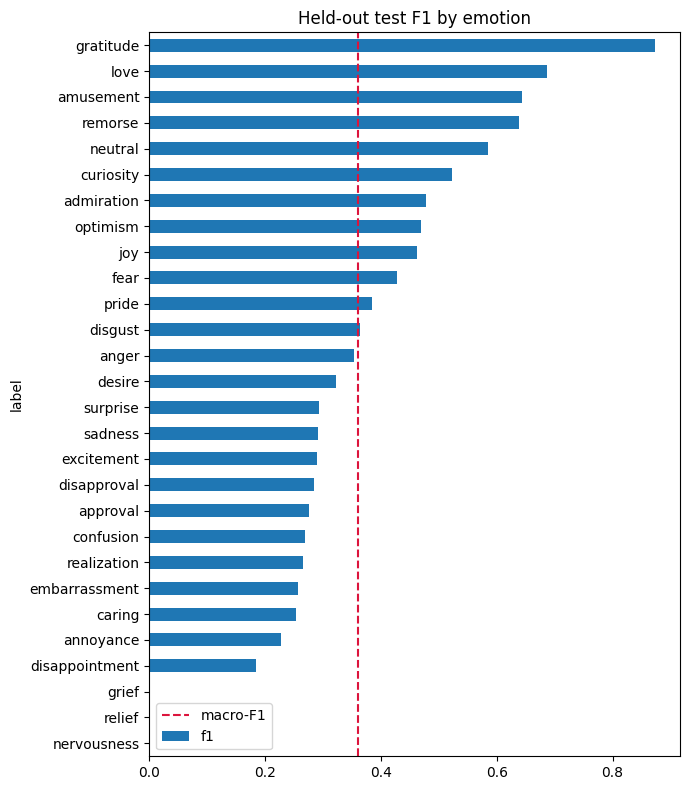

In [7]:
# Phase 10: refit on train+dev, test once, and perform error analysis
best_name = A
X_fit = pd.concat([SPLITS['train']['text'], SPLITS['dev']['text']], ignore_index=True)
Y_fit = np.vstack([TARGETS['train'], TARGETS['dev']])
X_test = SPLITS['test']['text']
Y_test = TARGETS['test']
final_model = clone(systems[best_name]).fit(X_fit, Y_fit)
test_probabilities = probability_array(final_model, X_test)
test_threshold = oof[best_name]['threshold']
test_predictions = (test_probabilities >= test_threshold).astype(int)
final_metrics = multilabel_metrics(Y_test, test_probabilities, test_threshold)
final_metrics['subset_accuracy'] = accuracy_score(Y_test, test_predictions)
print('Selected system:', best_name, '| global threshold:', test_threshold)
display(pd.Series(final_metrics, name=best_name).to_frame())

per_label = pd.DataFrame({
    'label': LABELS, 'support': Y_test.sum(axis=0),
    'predicted': test_predictions.sum(axis=0),
})
from sklearn.metrics import precision_recall_fscore_support
precision, recall, f1, _ = precision_recall_fscore_support(Y_test, test_predictions, average=None, zero_division=0)
per_label['precision'] = precision
per_label['recall'] = recall
per_label['f1'] = f1
per_label = per_label.sort_values('f1').reset_index(drop=True)
display(per_label)
per_label.plot.barh(x='label', y='f1', figsize=(7, 8), legend=False, title='Held-out test F1 by emotion')
plt.axvline(final_metrics['macro_f1'], color='crimson', linestyle='--', label='macro-F1')
plt.legend(); plt.tight_layout()
plt.savefig(PLOTS_DIR / 'per_emotion_test_f1.png', dpi=180, bbox_inches='tight')

def decode(row):
    return ', '.join(np.asarray(LABELS)[np.flatnonzero(row)]) or '<empty>'
error_mask = (Y_test != test_predictions).any(axis=1)
error_indices = np.flatnonzero(error_mask)[:20]
error_examples = pd.DataFrame({
    'text': X_test.iloc[error_indices].to_numpy(),
    'gold': [decode(Y_test[index]) for index in error_indices],
    'predicted': [decode(test_predictions[index]) for index in error_indices],
})
display(error_examples)

with open(RESULTS_DIR / 'run_config.json', 'w', encoding='utf-8') as handle:
    json.dump({'data_dir': str(DATA_DIR), 'cv_seeds': CV_SEEDS, 'n_splits': N_SPLITS,
               'bpe_vocab_size': BPE_VOCAB_SIZE, 'bpe_min_frequency': BPE_MIN_FREQUENCY,
               'threshold_candidates': THRESHOLDS.tolist(), 'rope': ROPE,
               'selected_system': best_name, 'selected_threshold': float(test_threshold)},
              handle, indent=2)

## Interpretation checklist

- Macro-F1 is primary because the 28 emotions are highly imbalanced.
- Micro-F1, precision, recall, Hamming loss, and subset accuracy expose different trade-offs.
- The global threshold is selected from training-fold validation predictions, never from the test set.
- The BPE vocabulary is trained once on the complete official training text, as chosen for this project.
- The final conclusion must be based on the rerun tables above, not on the stale outputs that were originally stored in this notebook.
- AI assistance and sources must be disclosed in the final blog/report.